# Occupancy 

In [1]:
import sys
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
np.random.seed(42)
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'data' / 'processed' / 'Charging_Data_clean.csv').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Could not find cleaned charging data from the current directory.')
sys.path.insert(0, str(ROOT / 'team' / 'mariam_availability'))
from src.occupancy import (load_sessions, build_intervals, validate_intervals,
                           charger_state_at, hourly_busy, hourly_occupancy_matrix)

### Build busy intervals

In [2]:
sessions = load_sessions(ROOT / "data" / "processed" / "Charging_Data_clean.csv")
intervals = build_intervals(sessions)
print(f"CLEAN SESSIONS\nRows     : {len(sessions):,}\nChargers : {sessions.charger_id.nunique()}")
print(f"INTERVALS\nRows              : {len(intervals):,}\nChargers          : {intervals.charger_id.nunique()}\nMean gap (min)    : {intervals.gap_before_min.mean():.2f}")
intervals[["charger_id", "start", "end", "prev_end", "gap_before_min", "seq"]].head()

CLEAN SESSIONS
Rows     : 441,064
Chargers : 92
INTERVALS
Rows              : 441,064
Chargers          : 92
Mean gap (min)    : 162.93


,charger_id,start,end,prev_end,gap_before_min,seq
0,1,2020-01-01 01:42:01,2020-01-01 01:43:59,NaT,NaN,0
1,1,2020-01-01 13:04:54,2020-01-01 13:08:35,2020-01-01 01:43:59,680.916667,1
2,1,2020-01-01 13:09:22,2020-01-01 13:11:03,2020-01-01 13:08:35,0.783333,2
3,1,2020-01-01 14:19:51,2020-01-01 14:21:51,2020-01-01 13:11:03,68.800000,3
4,1,2020-01-01 15:38:27,2020-01-01 15:40:08,2020-01-01 14:21:51,76.600000,4


Intervals are sorted within each charger. The first session per charger has no previous end, so its gap is missing by design.

### Validate interval timelines

In [3]:
counts = validate_intervals(intervals)
print("OVERLAP CHECK")
for key, value in counts.items():
    print(f"{key:30s}: {value}")
assert all(value == 0 for value in counts.values()), counts

OVERLAP CHECK
end_not_after_start           : 0
overlap_with_previous         : 0
overlap_with_any_earlier      : 0
chargers_not_sorted           : 0
duplicate_charger_start       : 0
missing_values                : 0
negative_gaps                 : 0


### Charger state at a timestamp

In [4]:
state = charger_state_at(intervals, "2021-10-15 13:00")
print(f"CHARGER STATE\nTimestamp       : 2021-10-15 13:00\nChargers        : {len(state)}\nBusy chargers   : {int(state.busy.sum())}\nFree chargers   : {int((~state.busy).sum())}")
state.head()

CHARGER STATE
Timestamp       : 2021-10-15 13:00
Chargers        : 92
Busy chargers   : 36
Free chargers   : 56


,busy,session_start,elapsed_min,true_end,true_remaining_min
1,False,NaT,NaN,NaT,NaN
2,False,NaT,NaN,NaT,NaN
3,False,NaT,NaN,NaT,NaN
4,True,2021-10-15 12:29:12,30.8,2021-10-15 14:12:13,72.216667
5,True,2021-10-15 12:46:36,13.4,2021-10-15 13:06:58,6.966667


### Hourly reconciliation

HOURLY RECONCILIATION
Busy minutes (sum) : 24,127,596.32
Duration minutes   : 24,127,596.32
Max charger-hour   : 60.00
Hours covered      : 17,469


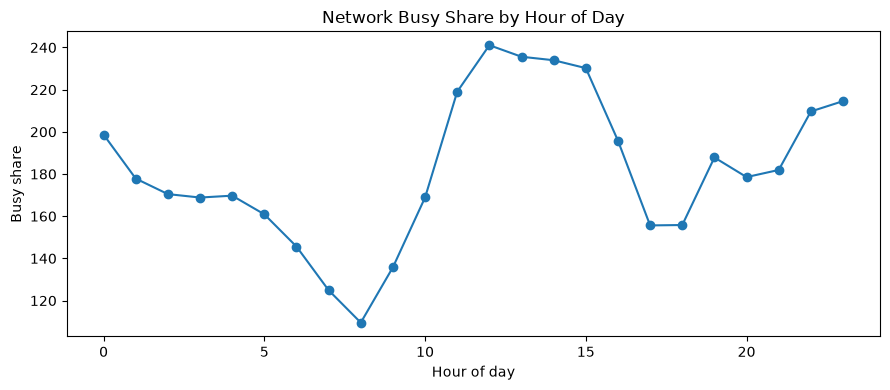

In [5]:
valid = intervals.loc[intervals.end > intervals.start]
hourly = hourly_busy(valid)
assert np.isclose(hourly.busy_min.sum(), valid.duration_min.sum(), rtol=1e-6)
assert hourly.busy_min.max() <= 60 + 1e-6
network = hourly.groupby(hourly.hour.dt.hour).busy_min.sum() / (60 * sessions.charger_id.nunique())
TABLES = ROOT / "team" / "mariam_availability" / "reports" / "tables"
TABLES.mkdir(parents=True, exist_ok=True)
audit = pd.Series({"sessions": len(sessions), "chargers": sessions.charger_id.nunique(),
                   "hours_covered": hourly.hour.nunique(), "busy_minutes": hourly.busy_min.sum(),
                   "session_duration_minutes": valid.duration_min.sum(),
                   "max_busy_minutes_per_charger_hour": hourly.busy_min.max(), **counts}, name="value")
audit.to_frame().to_csv(TABLES / "occupancy_audit.csv")
(hourly.assign(hour_of_day=hourly.hour.dt.hour).groupby("hour_of_day", as_index=False)
 .agg(charger_hours=("charger_id", "size"), busy_minutes=("busy_min", "sum"),
      mean_busy_minutes=("busy_min", "mean"))
 .to_csv(TABLES / "hourly_occupancy_distribution.csv", index=False))
print(f"HOURLY RECONCILIATION\nBusy minutes (sum) : {hourly.busy_min.sum():,.2f}\nDuration minutes   : {valid.duration_min.sum():,.2f}\nMax charger-hour   : {hourly.busy_min.max():.2f}\nHours covered      : {hourly.hour.nunique():,}")
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(network.index, network.values, marker="o")
ax.set(title="Network Busy Share by Hour of Day", xlabel="Hour of day", ylabel="Busy share")
fig.tight_layout(); plt.show()

The split preserves the session duration total and keeps each charger-hour at or below 60 busy minutes.

## Final Summary

In [6]:
print("FINAL SUMMARY")
print(f"Validation counts : {counts}")
print(f"Rows / chargers   : {len(intervals):,} / {intervals.charger_id.nunique()}")
print(f"Hours covered     : {hourly.hour.nunique():,}")


FINAL SUMMARY
Validation counts : {'end_not_after_start': 0, 'overlap_with_previous': 0, 'overlap_with_any_earlier': 0, 'chargers_not_sorted': 0, 'duplicate_charger_start': 0, 'missing_values': 0, 'negative_gaps': 0}
Rows / chargers   : 441,064 / 92
Hours covered     : 17,469
